# Phase 2 - Geographic extraction

This notebook runs the reproducible Bangladesh centroid extraction and displays its audit evidence.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
from IPython.display import Image, display

project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
subprocess.run([sys.executable, '-m', 'src.extract'], cwd=project_root, check=True, stdout=subprocess.DEVNULL)
audit = json.loads((project_root / 'reports/generated/geographic_extraction_audit.json').read_text(encoding='utf-8'))

In [2]:
{key: audit[key] for key in [
    'source_rows', 'bbox_candidate_rows', 'retained_rows',
    'unmatched_bbox_candidates', 'ambiguous_boundary_centroids',
    'duplicate_retained_quadkeys', 'missing_retained_geometry',
]}

{'source_rows': 3551267,
 'bbox_candidate_rows': 49213,
 'retained_rows': 15956,
 'unmatched_bbox_candidates': 33257,
 'ambiguous_boundary_centroids': 0,
 'duplicate_retained_quadkeys': 0,
 'missing_retained_geometry': 0}

In [3]:
audit['rows_by_adm1']

{'Barisal': 961,
 'Chittagong': 4022,
 'Dhaka': 4420,
 'Khulna': 1467,
 'Mymensingh': 709,
 'Rajshani': 1582,
 'Rangpur': 1524,
 'Sylhet': 1271}

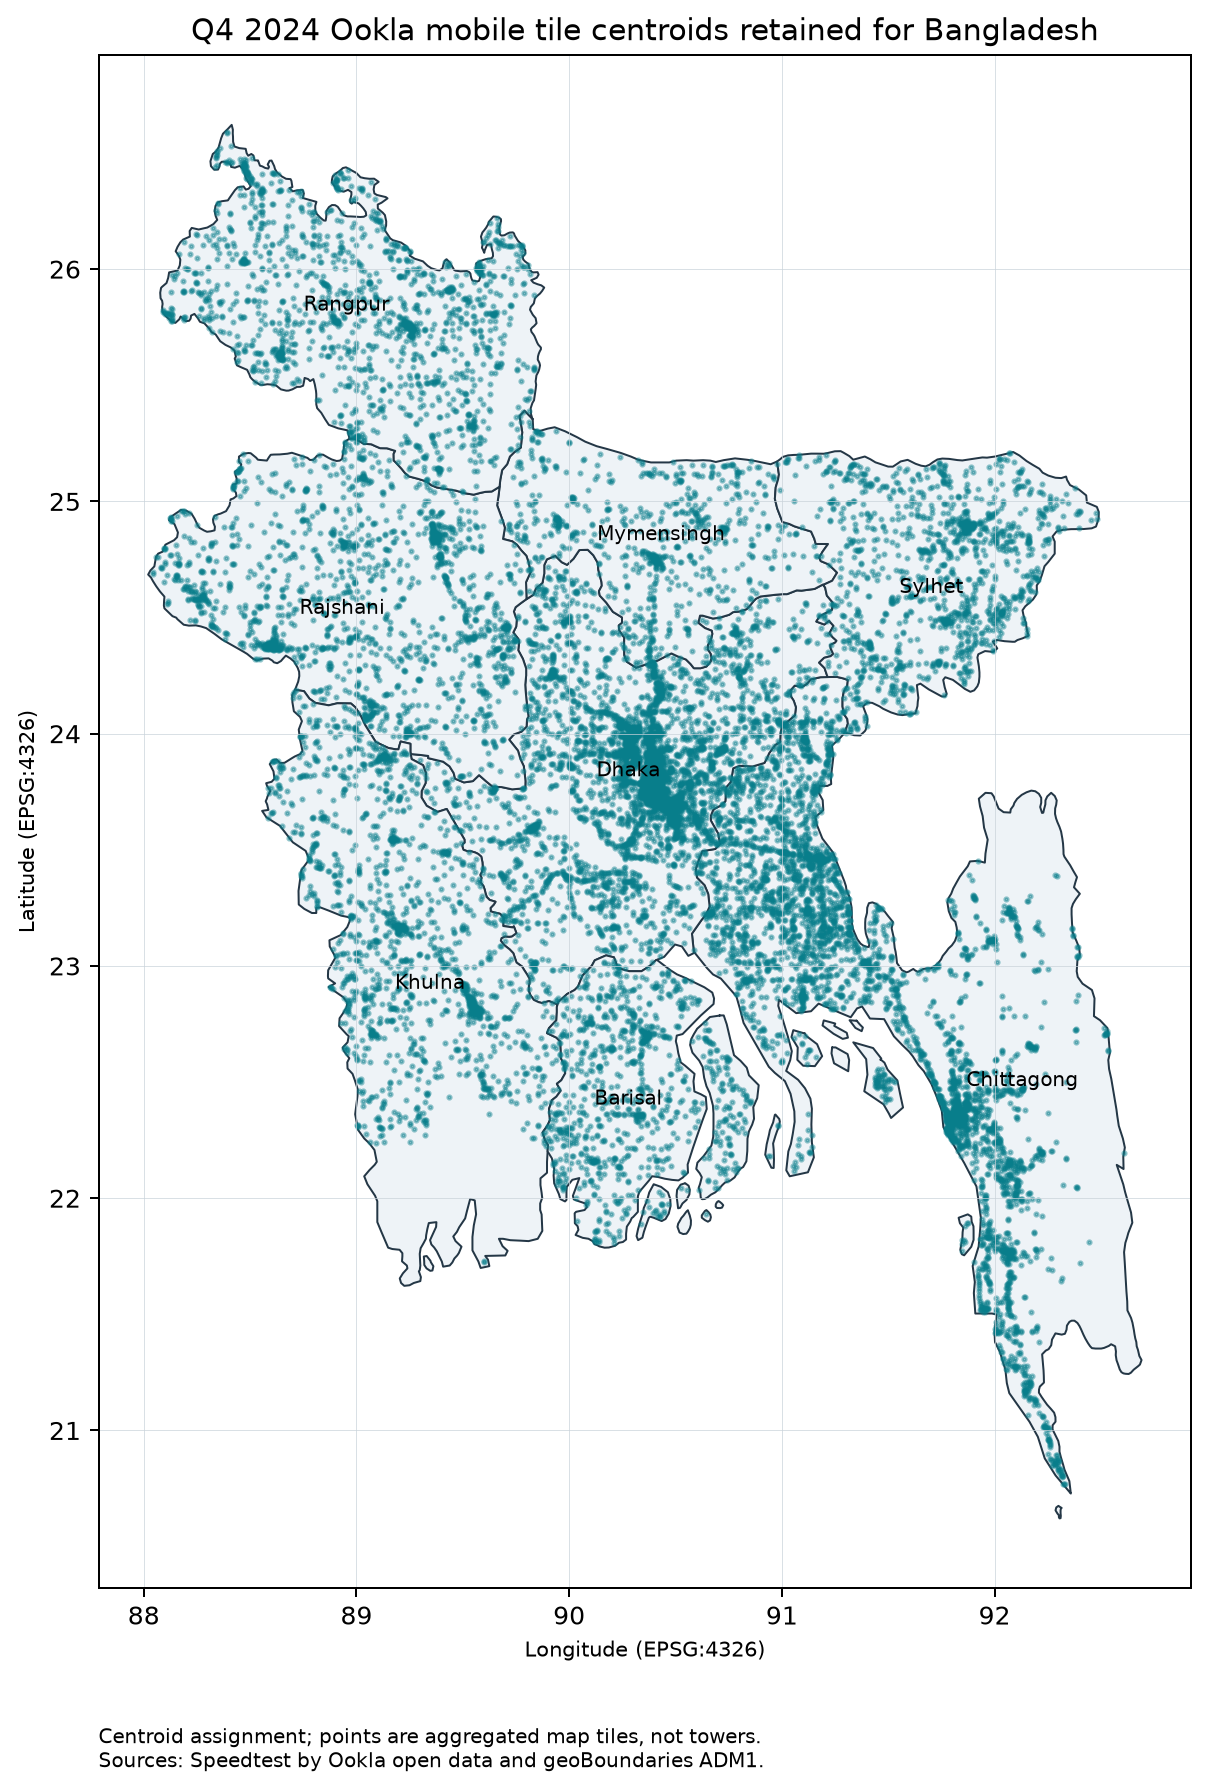

In [4]:
display(Image(filename=project_root / 'reports/figures/bgd_tile_centroids_2024_q4.png'))

## Interpretation

The map verifies geographic assignment and source coverage. Point density is affected by participation and must not be interpreted as cellular coverage or population density.